# HW Y · 02 — Round 2: combine the adopted changes, tune drop path, measure noise

**Round 1 adopted** drop path 0.2 and full-frame 448 × 600 input. The plan (`research/plan.md`, written before these runs)
specified four runs, all with full-frame input and an EMA copy:
- drop path 0.1 / 0.2 / 0.3
- drop path 0.2 again with seed 1, as a noise floor

**Rules:**
1. Pick the drop path rate by CV.
2. Keep the chosen run only if it beats full frame alone (paired CV gain > 0, ≥ 3/5 folds).
3. Re-test EMA with a cross-fitted CV score that removes best-epoch selection bias.
4. Call gains smaller than the seed-to-seed spread "within noise".

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HWY_DIR = Path.cwd() if (Path.cwd() / "isic").is_dir() else Path.cwd().parent
sys.path.insert(0, str(HWY_DIR)); sys.path.insert(0, str(HWY_DIR / "research"))
from isic import analysis as A
from isic.data import CLASSES

pd.set_option("display.width", 200)
la = lambda r: f"{r}_tta20_la"
BASE, R1_RECT, ADOPTED = "hwx/convnext_s_kd_res448_tta20_la", "cnx_kd_r1_rect_tta20_la", "cnx_kd_r1_rect_ema_tta20_la"

def run(cmd):
    print("$", cmd, flush=True)
    subprocess.run(cmd, shell=True, check=True, cwd=HWY_DIR)

RUNS = {"full frame + dp 0.1": "cnx_kd_r2_rect_dp01", "full frame + dp 0.2": "cnx_kd_r2_rect_dp02",
        "full frame + dp 0.3": "cnx_kd_r2_rect_dp03", "full frame + dp 0.2, seed 1": "cnx_kd_r2_rect_dp02_s1"}
RUN_TRAINING = False   # True on a GPU node: one fold of the seed-1 replicate (~42 min)
if RUN_TRAINING:
    run("python scripts/train_classifier.py --run-name cnx_kd_r2_rect_dp02_s1 --model convnext_small.fb_in22k_ft_in1k --lr 2e-4 "
        "--img-size 448 --img-width 600 --soft-labels results/hwx/soft_labels/bb5_calib_oof.csv --kd-alpha 0.5 --ema 0.999 "
        "--drop-path 0.2 --seed 1 --fold 0")

In [2]:
names = ["baseline (HW X)", "full frame (Round 1)"] + list(RUNS)
runs = [BASE, R1_RECT] + [la(r) for r in RUNS.values()]
display(A.summary(runs, names=names)[["bal_acc", "auc", "mel_sens"]])
display(A.summary(runs, split="cv_val", names=names, ensemble=False)[["bal_acc"]].rename(columns={"bal_acc": "cv_bal_acc"}))
A.paired_table([la(r) for r in RUNS.values()], R1_RECT, names=[f"{n} vs full frame alone" for n in RUNS])

,bal_acc,auc,mel_sens
baseline (HW X),0.864 ± 0.010,0.983 ± 0.001,0.795 ± 0.018
full frame (Round 1),0.864 ± 0.009,0.983 ± 0.001,0.819 ± 0.016
full frame + dp 0.1,0.869 ± 0.005,0.983 ± 0.001,0.812 ± 0.011
full frame + dp 0.2,0.866 ± 0.005,0.984 ± 0.001,0.830 ± 0.026
full frame + dp 0.3,0.870 ± 0.007,0.984 ± 0.001,0.841 ± 0.014
"full frame + dp 0.2, seed 1",0.861 ± 0.009,0.984 ± 0.001,0.828 ± 0.011


,cv_bal_acc
baseline (HW X),0.888 ± 0.020
full frame (Round 1),0.896 ± 0.012
full frame + dp 0.1,0.889 ± 0.016
full frame + dp 0.2,0.894 ± 0.014
full frame + dp 0.3,0.890 ± 0.018
"full frame + dp 0.2, seed 1",0.887 ± 0.009


,cv_bal_acc,cv_mel_sens,cv_auc,test_bal_acc,test_mel_sens,test_auc
full frame + dp 0.1 vs full frame alone,-0.007 ± 0.019 (2/5),-0.009 ± 0.017 (2/5),-0.001 ± 0.002 (2/5),+0.006 ± 0.008 (4/5),-0.007 ± 0.014 (2/5),+0.000 ± 0.001 (3/5)
full frame + dp 0.2 vs full frame alone,-0.002 ± 0.010 (3/5),-0.000 ± 0.036 (4/5),-0.000 ± 0.001 (2/5),+0.002 ± 0.012 (2/5),+0.012 ± 0.036 (3/5),+0.001 ± 0.000 (5/5)
full frame + dp 0.3 vs full frame alone,-0.006 ± 0.016 (2/5),+0.028 ± 0.029 (4/5),-0.001 ± 0.003 (2/5),+0.006 ± 0.005 (5/5),+0.022 ± 0.020 (4/5),+0.001 ± 0.002 (3/5)
"full frame + dp 0.2, seed 1 vs full frame alone",-0.009 ± 0.015 (1/5),+0.008 ± 0.011 (3/5),+0.000 ± 0.001 (4/5),-0.002 ± 0.002 (1/5),+0.009 ± 0.024 (3/5),+0.001 ± 0.001 (4/5)


## Noise floor: the same recipe with a different seed

,cv_val,official_test
seed 0,0.8938,0.8661
seed 1,0.8867,0.8613
seed 1 - seed 0,-0.0071,-0.0047


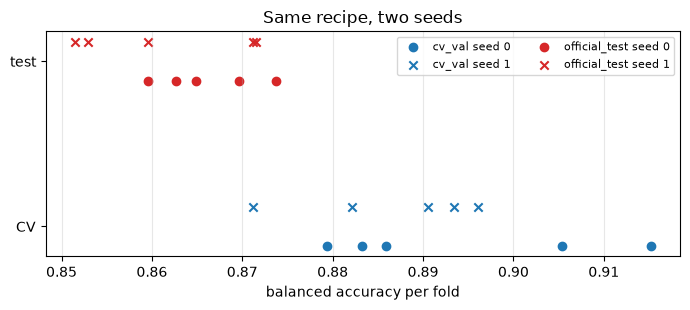

In [3]:
a, b = la(RUNS["full frame + dp 0.2"]), la(RUNS["full frame + dp 0.2, seed 1"])
t = pd.DataFrame({s: [A.per_fold(a, s).bal_acc.mean(), A.per_fold(b, s).bal_acc.mean()] for s in ("cv_val", "official_test")}, index=["seed 0", "seed 1"])
t.loc["seed 1 - seed 0"] = t.loc["seed 1"] - t.loc["seed 0"]
display(t.round(4))
fig, ax = plt.subplots(figsize=(7, 3.2))
for j, (s, col) in enumerate((("cv_val", "C0"), ("official_test", "C3"))):
    ax.scatter(A.per_fold(a, s).bal_acc, [j - 0.12] * 5, color=col, marker="o", label=f"{s} seed 0")
    ax.scatter(A.per_fold(b, s).bal_acc, [j + 0.12] * 5, color=col, marker="x", label=f"{s} seed 1")
ax.set_yticks([0, 1], ["CV", "test"]); ax.set_xlabel("balanced accuracy per fold"); ax.legend(fontsize=8, ncol=2); ax.grid(axis="x", alpha=.3)
ax.set_title("Same recipe, two seeds"); plt.tight_layout()

## EMA re-tested with a cross-fitted (selection-free) CV score

In [4]:
from round2_analysis import cross_fitted
rows = []
for n, r in RUNS.items():
    raw, ema = cross_fitted(r), cross_fitted(f"{r}_ema")
    best_raw, best_ema = A.history(r).groupby("fold").val_balanced_acc.max().mean(), A.history(r).groupby("fold").val_balanced_acc_ema.max().mean()
    rows.append({"run": n, "best-epoch raw": best_raw, "best-epoch EMA": best_ema, "cross-fitted raw": raw.mean(), "cross-fitted EMA": ema.mean(),
                 "cross-fitted EMA-raw": (ema - raw).mean(), "folds": f"{int(((ema - raw) > 0).sum())}/5",
                 "test EMA-raw (TTA+LA)": A.paired(la(f"{r}_ema"), la(r))[0]})
pd.DataFrame(rows).set_index("run").round(4)

,best-epoch raw,best-epoch EMA,cross-fitted raw,cross-fitted EMA,cross-fitted EMA-raw,folds,test EMA-raw (TTA+LA)
run,,,,,,,
full frame + dp 0.1,0.8432,0.8400,0.8254,0.8338,0.0084,4/5,-0.0031
full frame + dp 0.2,0.8493,0.8438,0.8421,0.8329,-0.0092,0/5,0.0073
full frame + dp 0.3,0.8506,0.8466,0.8390,0.8402,0.0012,2/5,0.0092
"full frame + dp 0.2, seed 1",0.8461,0.8404,0.8258,0.8261,0.0003,3/5,0.0036


## Takeaways
* **Drop path 0.2** is the best rate (CV 0.894). Combined with full frame, it does **not** beat full frame alone on CV
  (−0.002), so full frame alone stays.
* **EMA** wins the cross-fitted CV score in 3 of 4 runs, so it is adopted, but only by +0.0002. The best-epoch scores
  (first two columns) are 0.01 higher than the cross-fitted ones; that difference is the selection bonus.
* **Noise floor:** the seed-1 replicate moves the 5-fold mean by −0.007 on CV and −0.005 on test. Every gain from Rounds
  1–2 is this size. **Round-2 model: full frame + EMA, CV 0.894, test 0.867.**